# Iris：从四个测量值识别花的品种

目标：学习三分类。输入是花萼长、花萼宽、花瓣长、花瓣宽，输出是三个品种的得分。数据读取放在本地 `examples/data/data.py`，本页只关注训练。

从项目根目录运行。`device` 可选 `"cpu"`、`"apple"` 或 `"cuda"`；不固定随机种子。

In [5]:
from qutai import Stream, nn, visualization
from examples.data.data import IRIS_NAMES, load_iris

device = "apple"

## 1. 看数据

表格先展示原始厘米数。随后除以各列的大致量程，让四个特征处于相近范围。每五条留一条作测试，其余用于训练，三种花都会出现在两个集合中。

In [6]:
inputs, targets = load_iris()
visualization.Table([row + [IRIS_NAMES[target]] for row, target in zip(inputs[::50], targets[::50])], columns=["花萼长", "花萼宽", "花瓣长", "花瓣宽", "品种"])

花萼长,花萼宽,花瓣长,花瓣宽,品种
5.1,3.5,1.4,0.2,setosa
7.0,3.2,4.7,1.4,versicolor
6.3,3.3,6.0,2.5,virginica


In [7]:
inputs = [[value / scale for value, scale in zip(row, [8, 5, 7, 3])] for row in inputs]
test_inputs, test_targets = inputs[::5], targets[::5]
inputs = [row for index, row in enumerate(inputs) if index % 5]
targets = [target for index, target in enumerate(targets) if index % 5]

## 2. 搭模型

最后一层输出三个原始得分。`CrossEntropy` 直接接收这些得分和正确类别编号，不需要先加 Softmax。

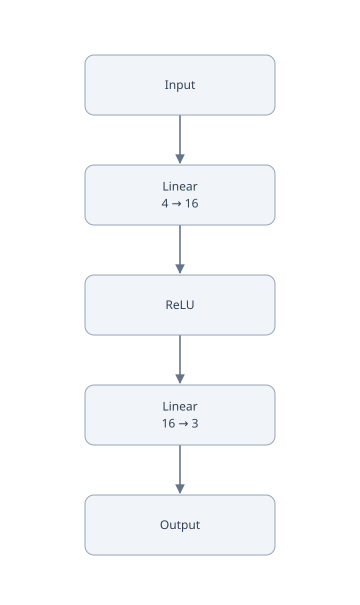

In [8]:
model = nn.Model([
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 3)
], device=device)
optimizer = nn.AdamW(model, learning_rate=0.02)
loss_function = nn.CrossEntropy()
data = Stream(inputs, targets, batch_size=16, device=device)
epochs = 20

visualization.Network(model)

## 3. 训练

与回归保持相同的 epoch、批次和四步更新。变化的是模型、损失函数，以及目标从数字变成了类别编号。

In [9]:
# 每轮遍历一次数据；每批独立完成一次参数更新。
for epoch in range(epochs):
    for inputs, targets in data:
        optimizer.zero_grad()
        loss = loss_function(model(inputs), targets)
        loss.backward()
        optimizer.step()
    print(f"epoch {epoch + 1}/{epochs}  loss {loss.item():.6f}")

epoch 1/20  loss 0.996366
epoch 2/20  loss 0.818658
epoch 3/20  loss 0.610579
epoch 4/20  loss 0.649452
epoch 5/20  loss 0.509095
epoch 6/20  loss 0.318391
epoch 7/20  loss 0.419061
epoch 8/20  loss 0.349977
epoch 9/20  loss 0.382021
epoch 10/20  loss 0.288559
epoch 11/20  loss 0.261099
epoch 12/20  loss 0.138899
epoch 13/20  loss 0.118364
epoch 14/20  loss 0.258817
epoch 15/20  loss 0.128492
epoch 16/20  loss 0.115459
epoch 17/20  loss 0.139382
epoch 18/20  loss 0.021242
epoch 19/20  loss 0.317050
epoch 20/20  loss 0.052102


## 4. 看结果

`argmax` 取最高分对应的类别。测试集没有参与参数更新，因此比训练集更适合检查模型是否学会了分类。

In [10]:
predictions = model(test_inputs, train=False).argmax(axis=-1)
correct = sum(prediction == target for prediction, target in zip(predictions, test_targets))
print(f"测试准确率：{correct}/{len(test_targets)} = {correct / len(test_targets):.1%}")

visualization.Table([[IRIS_NAMES[target], IRIS_NAMES[prediction]] for target, prediction in zip(test_targets[:6], predictions[:6])], columns=["正确品种", "预测品种"])

测试准确率：29/30 = 96.7%


正确品种,预测品种
setosa,setosa
setosa,setosa
setosa,setosa
setosa,setosa
setosa,setosa
setosa,setosa
